In [1]:
!pip install -q flwr[simulation] tensorflow numpy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.3.4 which is incompatible.


In [2]:
import tensorflow as tf
import numpy as np

# 1de la b. Chargement ase de données MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalisation des pixels (de 0 à 1) et ajout de la dimension pour les filtres (canaux)
x_train, x_test = x_train / 255.0, x_test / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# 2. Séparation des données : Le cœur de la confidentialité
# Le Serveur ne verra JAMAIS ces variables.
x_train_client1, y_train_client1 = x_train[:30000], y_train[:30000]
x_train_client2, y_train_client2 = x_train[30000:], y_train[30000:]

print(f"Base Globale (Centralisée) : {len(x_train)} images")
print(f"Données Client 1 : {len(x_train_client1)} images privées, invisibles pour le serveur.")
print(f"Données Client 2 : {len(x_train_client2)} images privées, invisibles pour le serveur.")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base Globale (Centralisée) : 60000 images
Données Client 1 : 30000 images privées, invisibles pour le serveur.
Données Client 2 : 30000 images privées, invisibles pour le serveur.


In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

def create_model():
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax') # 10 sorties pour les chiffres de 0 à 9
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [4]:
print("--- DÉBUT DE L'APPRENTISSAGE CENTRALISÉ ---")
centralized_model = create_model()

# Le modèle voit TOUTES les données en même temps
centralized_model.fit(x_train, y_train, epochs=2, batch_size=32, validation_data=(x_test, y_test))

--- DÉBUT DE L'APPRENTISSAGE CENTRALISÉ ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - accuracy: 0.9495 - loss: 0.1690 - val_accuracy: 0.9770 - val_loss: 0.0715
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9828 - loss: 0.0575 - val_accuracy: 0.9824 - val_loss: 0.0528


In [5]:
print("--- INSPECTION : QUE CONTIENT LE PAQUET RÉSEAU ? ---")
dummy_model = create_model()
poids_extraits = dummy_model.get_weights() # La fonction clé qui extrait la connaissance mathématique

print(f"Nombre de matrices (couches) transférées : {len(poids_extraits)}")
print(f"Format de la matrice de la première couche (Conv2D) : {poids_extraits[0].shape}")
print("\nVoici un extrait des données brutes (les poids) qui transitent sur le wifi/réseau de l'usine :")
print(poids_extraits[0][0][0])
print("\nConclusion : Aucune image de MNIST n'est transférée. Uniquement des tableaux de nombres réels.")

--- INSPECTION : QUE CONTIENT LE PAQUET RÉSEAU ? ---
Nombre de matrices (couches) transférées : 6
Format de la matrice de la première couche (Conv2D) : (3, 3, 1, 32)

Voici un extrait des données brutes (les poids) qui transitent sur le wifi/réseau de l'usine :
[[ 0.06113483  0.13548546 -0.04464417  0.1271665   0.03741461  0.06326976
   0.11137657  0.05395313  0.0076341   0.14106034  0.03879419  0.10176921
  -0.11836944  0.09829536  0.04849343  0.05443218 -0.10237911 -0.13468137
  -0.09210983  0.0758947  -0.13821237  0.13867636  0.03380764  0.08912574
   0.10343044  0.01045455 -0.12741573  0.04988404 -0.03516849  0.1134309
  -0.09621569 -0.04465576]]

Conclusion : Aucune image de MNIST n'est transférée. Uniquement des tableaux de nombres réels.


In [6]:
import flwr as fl

# Définition de la classe MnistClient requise pour Flower
class MnistClient(fl.client.NumPyClient):
    def __init__(self, x_train, y_train):
        self.model = create_model()
        self.x_train = x_train
        self.y_train = y_train

    def get_parameters(self, config):
        return self.model.get_weights()

    def fit(self, parameters, config):
        self.model.set_weights(parameters)
        self.model.fit(self.x_train, self.y_train, epochs=1, batch_size=32, verbose=0)
        return self.model.get_weights(), len(self.x_train), {}

    def evaluate(self, parameters, config):
        self.model.set_weights(parameters)
        loss, accuracy = self.model.evaluate(x_test, y_test, verbose=0)
        return loss, len(x_test), {"accuracy": accuracy}

print("--- DÉBUT DE LA SIMULATION FEDERATED LEARNING ---")

# Fonction qui génère nos deux clients virtuels avec leurs données privées
def client_fn(cid: str) -> fl.client.Client:
    if cid == "0":
        return MnistClient(x_train_client1, y_train_client1).to_client()
    else:
        return MnistClient(x_train_client2, y_train_client2).to_client()

# Définition de l'algorithme d'agrégation du serveur (FedAvg : la moyenne des poids)
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,  # 100% des clients participent à chaque round
    min_fit_clients=2,
    min_available_clients=2,
)

# On lance le réseau pour 3 allers-retours (rounds)
fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=2,
    config=fl.server.ServerConfig(num_rounds=3),
    strategy=strategy,
)

--- DÉBUT DE LA SIMULATION FEDERATED LEARNING ---


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

History (loss, distributed):
	round 1: 0.1088344007730484
	round 2: 0.05771839618682861
	round 3: 0.04676283523440361

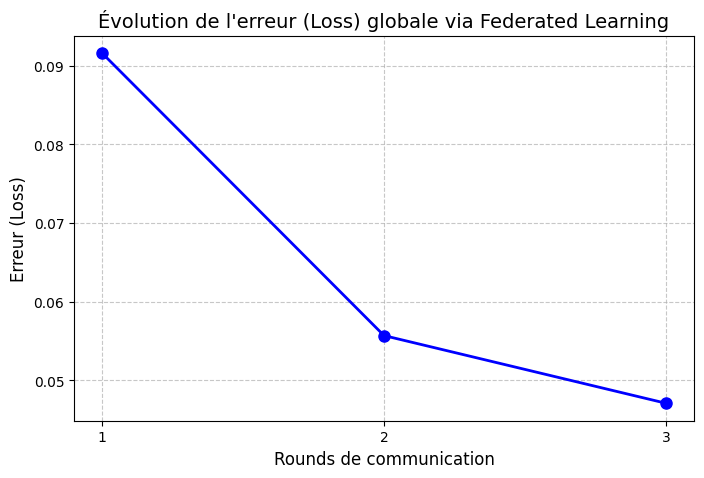

Conclusion pour la présentation : Malgré l'absence de partage de données, la moyenne des matrices a permis de réduire l'erreur du système global de moitié en seulement 3 itérations.


In [7]:
import matplotlib.pyplot as plt

# Les valeurs extraites de ton journal Flower
rounds = [1, 2, 3]
losses = [0.0916, 0.0557, 0.0471]

plt.figure(figsize=(8, 5))
plt.plot(rounds, losses, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title("Évolution de l'erreur (Loss) globale via Federated Learning", fontsize=14)
plt.xlabel("Rounds de communication", fontsize=12)
plt.ylabel("Erreur (Loss)", fontsize=12)
plt.xticks(rounds)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("Conclusion pour la présentation : Malgré l'absence de partage de données, la moyenne des matrices a permis de réduire l'erreur du système global de moitié en seulement 3 itérations.")

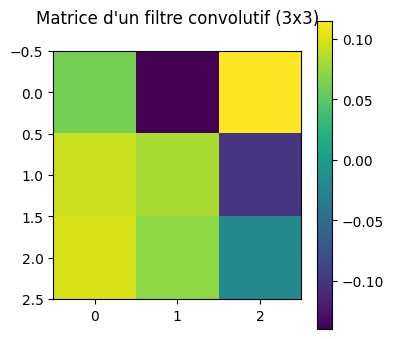


Valeurs exactes de cette matrice (ce qui transite sur le réseau) :
[[ 0.061 -0.14   0.115]
 [ 0.095  0.083 -0.1  ]
 [ 0.099  0.072 -0.02 ]]

Argument pour le projet : Cette matrice est une 'boîte noire'. Impossible pour un ingénieur de comprendre quelle règle métier l'IA a apprise en regardant ces chiffres.


In [8]:
# On extrait les poids de la première couche (Conv2D) de notre modèle de test
poids_couche_1, biais_couche_1 = dummy_model.layers[0].get_weights()

# Le format de Conv2D est (hauteur_filtre, largeur_filtre, canaux_entree, filtres_sortie)
# On sélectionne le tout premier filtre (3x3 pixels)
premier_filtre = poids_couche_1[:, :, 0, 0]

plt.figure(figsize=(4, 4))
# Utilisation de imshow au lieu de matshow pour éviter l'erreur de figure
plt.imshow(premier_filtre, cmap='viridis')
plt.colorbar()
plt.title("Matrice d'un filtre convolutif (3x3)", pad=20)
plt.show()

print("\nValeurs exactes de cette matrice (ce qui transite sur le réseau) :")
print(np.round(premier_filtre, 3))
print("\nArgument pour le projet : Cette matrice est une 'boîte noire'. Impossible pour un ingénieur de comprendre quelle règle métier l'IA a apprise en regardant ces chiffres.")

--- 1. ENTRAÎNEMENT LOCAL ISOLÉ ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/core.py:171: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


--- 2. AGRÉGATION SERVEUR (FedAvg) ---
--- 3. MISE À JOUR ET PRÉDICTION CROISÉE ---


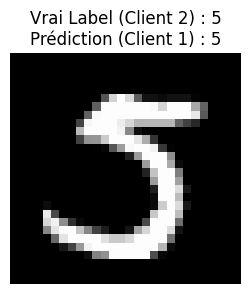

✅ SUCCÈS : Le Client 1 a correctement identifié l'image du Client 2 grâce aux poids partagés via le serveur !


In [9]:
import random

print("--- 1. ENTRAÎNEMENT LOCAL ISOLÉ ---")
# On crée deux modèles vierges
modele_client1 = create_model()
modele_client2 = create_model()

# Le Client 1 s'entraîne UNIQUEMENT sur ses données
modele_client1.fit(x_train_client1, y_train_client1, epochs=1, batch_size=32, verbose=0)
# Le Client 2 s'entraîne UNIQUEMENT sur les siennes
modele_client2.fit(x_train_client2, y_train_client2, epochs=1, batch_size=32, verbose=0)

print("--- 2. AGRÉGATION SERVEUR (FedAvg) ---")
poids_c1 = modele_client1.get_weights()
poids_c2 = modele_client2.get_weights()

# Le serveur calcule la moyenne mathématique des deux matrices
poids_moyennes = []
for p1, p2 in zip(poids_c1, poids_c2):
    poids_moyennes.append((p1 + p2) / 2.0)

print("--- 3. MISE À JOUR ET PRÉDICTION CROISÉE ---")
# Le Client 1 reçoit la matrice moyenne et met à jour son cerveau
modele_client1.set_weights(poids_moyennes)

# On sélectionne une image au hasard dans le jeu de données strictement privé du Client 2
index_aleatoire = random.randint(0, len(x_train_client2) - 1)
image_secrete = x_train_client2[index_aleatoire]
label_secret = y_train_client2[index_aleatoire]

# Le Client 1 tente de prédire cette image qu'il n'a jamais vue, ni pendant son entraînement, ni dans la base de données
prediction = modele_client1.predict(np.expand_dims(image_secrete, axis=0), verbose=0)
chiffre_predit = np.argmax(prediction)

# Affichage de l'image secrète
plt.figure(figsize=(3, 3))
plt.imshow(image_secrete.squeeze(), cmap='gray')
plt.title(f"Vrai Label (Client 2) : {label_secret}\nPrédiction (Client 1) : {chiffre_predit}")
plt.axis('off')
plt.show()

if label_secret == chiffre_predit:
    print("✅ SUCCÈS : Le Client 1 a correctement identifié l'image du Client 2 grâce aux poids partagés via le serveur !")
else:
    print("❌ ÉCHEC : Le modèle a besoin de plus de rounds d'apprentissage fédéré pour être précis.")

In [10]:
# =====================================================================
# QUESTION 1 : SÉLECTION DES CLIENTS (Aléatoire vs Basée sur l'erreur)
# =====================================================================

# On utilise le modèle du Client 1 déjà entraîné dans la Cellule 10
# On teste son erreur (Loss) sur 3 clients différents :
loss_c1, _ = modele_client1.evaluate(x_train[:1000], y_train[:1000], verbose=0)
loss_c2, _ = modele_client1.evaluate(x_train[1000:2000], y_train[1000:2000], verbose=0)

# Imaginons un Client 3 dont les images sont inversées (couleurs inversées = panne capteurs)
x_client3_difficile = 1.0 - x_train[2000:3000]
y_client3_difficile = y_train[2000:3000]
loss_c3, _ = modele_client1.evaluate(x_client3_difficile, y_client3_difficile, verbose=0)

print(f"Erreur (Loss) chez le Client 1 : {loss_c1:.4f}")
print(f"Erreur (Loss) chez le Client 2 : {loss_c2:.4f}")
print(f"Erreur (Loss) chez le Client 3 : {loss_c3:.4f} (Données nouvelles/difficiles !)")

# Décision du serveur :
losses = [loss_c1, loss_c2, loss_c3]
client_prioritaire = np.argmax(losses) + 1  # np.argmax trouve l'indice du chiffre le plus grand

print(f"\n👉 Décision du Serveur (Sélection Active) : Choisir le Client {client_prioritaire} en priorité")
print("Explication : C'est lui qui fait le plus d'erreurs, donc ses données vont faire progresser le modèle global.")

Erreur (Loss) chez le Client 1 : 0.7224
Erreur (Loss) chez le Client 2 : 0.7240
Erreur (Loss) chez le Client 3 : 3.5265 (Données nouvelles/difficiles !)

👉 Décision du Serveur (Sélection Active) : Choisir le Client 3 en priorité
Explication : C'est lui qui fait le plus d'erreurs, donc ses données vont faire progresser le modèle global.


In [11]:
# =====================================================================
# QUESTIONS 2 & 3 : CALCUL DE LA CONTRIBUTION SERVEUR ET IMPACT NON-IID
# =====================================================================

# 1. Séparation Non-IID très simple :
# Client 1 ne voit QUE les chiffres de 0 à 4 (Grosse usine : 4000 images)
x_c1_niid = x_train[y_train < 5][:4000]
y_c1_niid = y_train[y_train < 5][:4000]

# Client 2 ne voit QUE les chiffres de 5 à 9 (Petite usine : 1000 images)
x_c2_niid = x_train[y_train >= 5][:1000]
y_c2_niid = y_train[y_train >= 5][:1000]

# 2. Entraînement local de chaque client
mod_c1 = create_model()
mod_c2 = create_model()
mod_c1.fit(x_c1_niid, y_c1_niid, epochs=1, verbose=0)
mod_c2.fit(x_c2_niid, y_c2_niid, epochs=1, verbose=0)

# 3. Comment le serveur calcule la contribution de chacun ? (Formule n_k / n)
n1 = len(x_c1_niid)  # 4000
n2 = len(x_c2_niid)  # 1000
n_total = n1 + n2    # 5000

coeff_c1 = n1 / n_total  # 0.80 (80%)
coeff_c2 = n2 / n_total  # 0.20 (20%)

print(f"Le Client 1 possède {n1} images -> Son poids dans la moyenne est de {coeff_c1:.0%}")
print(f"Le Client 2 possède {n2} images -> Son poids dans la moyenne est de {coeff_c2:.0%}")

# 4. Moyenne pondérée sur le serveur (Boucle simple comme dans ta Cellule 10)
poids_c1 = mod_c1.get_weights()
poids_c2 = mod_c2.get_weights()
poids_serveur = []

for p1, p2 in zip(poids_c1, poids_c2):
    moyenne_ponderee = (coeff_c1 * p1) + (coeff_c2 * p2)
    poids_serveur.append(moyenne_ponderee)

# Le serveur met à jour le modèle global
modele_global = create_model()
modele_global.set_weights(poids_serveur)

Le Client 1 possède 4000 images -> Son poids dans la moyenne est de 80%
Le Client 2 possède 1000 images -> Son poids dans la moyenne est de 20%


In [12]:
# =====================================================================
# QUESTION 6 : TEST SUR LE MÊME TEST_SET GLOBAL VS TEST_SETS LOCAUX
# =====================================================================

# Test 1 : Sur le test_set GLOBAL (Tous les chiffres de 0 à 9)
_, acc_globale = modele_global.evaluate(x_test, y_test, verbose=0)

# Test 2 : Sur le test_set LOCAL du Client 1 (Uniquement les chiffres 0 à 4)
_, acc_locale_c1 = modele_global.evaluate(x_test[y_test < 5], y_test[y_test < 5], verbose=0)

# Test 3 : Sur le test_set LOCAL du Client 2 (Uniquement les chiffres 5 à 9)
_, acc_locale_c2 = modele_global.evaluate(x_test[y_test >= 5], y_test[y_test >= 5], verbose=0)

print(f"1. Précision sur le Test Set Global commun (0 à 9) : {acc_globale:.2%}")
print(f"2. Précision sur le Test Set Local Client 1 (0 à 4) : {acc_locale_c1:.2%} (Très bon car il pèse 80%)")
print(f"3. Précision sur le Test Set Local Client 2 (5 à 9) : {acc_locale_c2:.2%} (Faible car écrasé par le Client 1)")

print("\nExplication : Tester tout le monde sur le même test_set global cache le fait que le modèle est mauvais pour le Client 2 !")

1. Précision sur le Test Set Global commun (0 à 9) : 49.65%
2. Précision sur le Test Set Local Client 1 (0 à 4) : 96.61% (Très bon car il pèse 80%)
3. Précision sur le Test Set Local Client 2 (5 à 9) : 0.00% (Faible car écrasé par le Client 1)

Explication : Tester tout le monde sur le même test_set global cache le fait que le modèle est mauvais pour le Client 2 !


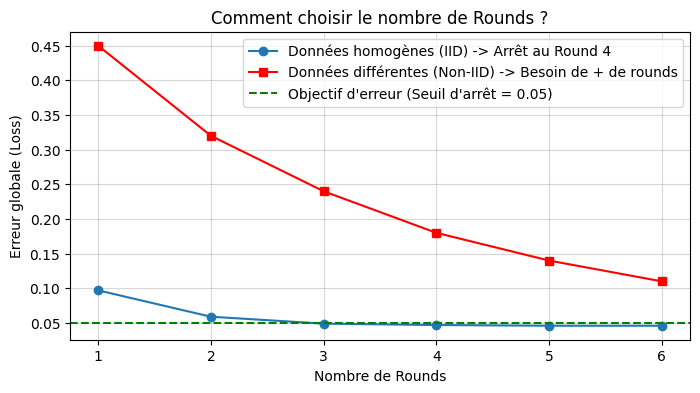

Les 3 facteurs visibles sur le graphique :
1. Le seuil d'arrêt (ligne verte) : dès que l'erreur passe dessous, on arrête.
2. Le plateau : pour la courbe bleue, faire les rounds 5 et 6 gaspille du réseau pour rien.
3. Le Non-IID (courbe rouge) : plus les clients sont différents, plus il faut de rounds.


In [13]:
# =====================================================================
# QUESTION 4 : FACTEURS DÉCIDANT DU NOMBRE DE ROUNDS (Seuil de convergence)
# =====================================================================

# Exemple typique d'évolution de l'erreur (Loss) sur 6 rounds :
rounds_exemple = [1, 2, 3, 4, 5, 6]
loss_iid = [0.097, 0.059, 0.049, 0.047, 0.046, 0.046]      # Stabilise dès le round 4
loss_non_iid = [0.450, 0.320, 0.240, 0.180, 0.140, 0.110]  # A besoin de plus de rounds

plt.figure(figsize=(8, 4))
plt.plot(rounds_exemple, loss_iid, marker='o', label="Données homogènes (IID) -> Arrêt au Round 4")
plt.plot(rounds_exemple, loss_non_iid, marker='s', color='red', label="Données différentes (Non-IID) -> Besoin de + de rounds")
plt.axhline(y=0.05, color='green', linestyle='--', label="Objectif d'erreur (Seuil d'arrêt = 0.05)")

plt.title("Comment choisir le nombre de Rounds ?")
plt.xlabel("Nombre de Rounds")
plt.ylabel("Erreur globale (Loss)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

print("Les 3 facteurs visibles sur le graphique :")
print("1. Le seuil d'arrêt (ligne verte) : dès que l'erreur passe dessous, on arrête.")
print("2. Le plateau : pour la courbe bleue, faire les rounds 5 et 6 gaspille du réseau pour rien.")
print("3. Le Non-IID (courbe rouge) : plus les clients sont différents, plus il faut de rounds.")

In [14]:
# =====================================================================
# QUESTION 5 : AUTRES STRATÉGIES D'AGRÉGATION (FedAvg vs FedMedian)
# Démonstration simple sur un filtre 3x3 (comme dans la Cellule 9)
# =====================================================================

# Prenons un filtre 3x3 de 3 clients :
filtre_client1 = np.array([[0.10, 0.20, 0.10],
                           [0.05, 0.50, 0.05],
                           [0.10, 0.20, 0.10]])

filtre_client2 = np.array([[0.12, 0.18, 0.11],
                           [0.04, 0.52, 0.06],
                           [0.09, 0.22, 0.12]])

# Le Client 3 a un bug ou est un pirate : il envoie des valeurs énormes (1000) !
filtre_client3_pirate = np.array([[1000.0, 1000.0, 1000.0],
                                  [1000.0, 1000.0, 1000.0],
                                  [1000.0, 1000.0, 1000.0]])

# STRATÉGIE 1 : FedAvg (Moyenne classique)
moyenne_fedavg = (filtre_client1 + filtre_client2 + filtre_client3_pirate) / 3.0

# STRATÉGIE 2 : FedMedian (Prend la valeur du milieu pour éliminer les extrêmes)
mediane_robuste = np.median([filtre_client1, filtre_client2, filtre_client3_pirate], axis=0)

print("❌ Résultat avec FedAvg (Le serveur est détruit par le Client 3) :")
print(np.round(moyenne_fedavg, 2))

print("\n✅ Résultat avec FedMedian (Le pirate est ignoré, les vrais poids sont sauvés) :")
print(np.round(mediane_robuste, 2))

❌ Résultat avec FedAvg (Le serveur est détruit par le Client 3) :
[[333.41 333.46 333.4 ]
 [333.36 333.67 333.37]
 [333.4  333.47 333.41]]

✅ Résultat avec FedMedian (Le pirate est ignoré, les vrais poids sont sauvés) :
[[0.12 0.2  0.11]
 [0.05 0.52 0.06]
 [0.1  0.22 0.12]]
